# **Classifying Colon Cancer Cells in Histology Images**

Convolutional neural networks that classify 27×27 pixel images of individual colon cells by whether the cell is cancerous, and by cell type (epithelial, fibroblast, inflammatory or other).

### Authors
Joseph Mchaileh
Robert Harper


In [ ]:
# Load relevant packages
import numpy as np # For working with numbers
import pandas as pd  #For working with dataframes
import zipfile # For unzipping files
import os
# For making plots
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf # For neural networks
from skimage.io import imread # For loading images

In [ ]:
# Colab directory setup
from google.colab import drive
drive.mount("/content/drive")
zip_path = "/content/drive/MyDrive/Image_classification_data.zip"  # Update to where the data is saved in Google Drive

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## **Load data**

In [ ]:
# Extract data from zip files
with zipfile.ZipFile(zip_path,'r') as zip_ref:
    zip_ref.extractall('./')

main_data = pd.read_csv('./data_labels_mainData.csv') #Main data
extra_data = pd.read_csv('./data_labels_extraData.csv') #Extra Data

In [ ]:
# Create full path column for each image in dataset
image_dir = "./patch_images"
main_data['image_path'] = main_data['ImageName'].apply(lambda x: os.path.join(image_dir, x)) # create new column with full path to each image
extra_data['image_path'] = extra_data['ImageName'].apply(lambda x: os.path.join(image_dir, x)) # create new column with full path to each image

In [ ]:
# Check data has been loaded successfully
print(main_data.shape)
main_data.head()

(9896, 7)


,InstanceID,patientID,ImageName,cellTypeName,cellType,isCancerous,image_path
0,22405,1,22405.png,fibroblast,0,0,./patch_images/22405.png
1,22406,1,22406.png,fibroblast,0,0,./patch_images/22406.png
2,22407,1,22407.png,fibroblast,0,0,./patch_images/22407.png
3,22408,1,22408.png,fibroblast,0,0,./patch_images/22408.png
4,22409,1,22409.png,fibroblast,0,0,./patch_images/22409.png


In [ ]:
# Inspect main data
main_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9896 entries, 0 to 9895
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   InstanceID    9896 non-null   int64 
 1   patientID     9896 non-null   int64 
 2   ImageName     9896 non-null   object
 3   cellTypeName  9896 non-null   object
 4   cellType      9896 non-null   int64 
 5   isCancerous   9896 non-null   int64 
 6   image_path    9896 non-null   object
dtypes: int64(4), object(3)
memory usage: 541.3+ KB


In [ ]:
# How many patients are represented in the data?
main_data["patientID"].unique()

array([ 1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17,
       18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34,
       35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51,
       52, 53, 54, 55, 56, 57, 58, 59, 60])

In [ ]:
# Convert target labels to strings (Req'd for image data generation)
main_data['isCancerous'] = main_data['isCancerous'].astype('str')
extra_data['isCancerous'] = extra_data['isCancerous'].astype('str')
main_data['cellType'] = main_data['cellType'].astype('str')

In [ ]:
# Inspect extra data
print(extra_data.shape)
extra_data.head()

(10384, 5)


,InstanceID,patientID,ImageName,isCancerous,image_path
0,12681,61,12681.png,0,./patch_images/12681.png
1,12682,61,12682.png,0,./patch_images/12682.png
2,12683,61,12683.png,0,./patch_images/12683.png
3,12684,61,12684.png,0,./patch_images/12684.png
4,12685,61,12685.png,0,./patch_images/12685.png


## **Data Splitting Strategy**

*  Group-based splitting was performed using GroupShuffleSplit instead of a random train-test split to avoid data leakage. Including samples from the same patient across training, validation, and test sets can lead to severe underestimation of validation and test error (S. Kapoor and A. Narayanan, 2023; S. Saeb et al., 2017; E. Chaibub Neto et al., 2017).

* Hold-out validation is used as a means of measuring performance. This is preferrered over other methods like k-fold cross validation, as CNN training is already time consuming, and our dataset contains a large number of images, therefore it is unnecessary to repeat training k-times. Hold-out validation is simpler and faster and better suited for CNNs.

* Stratified sampling was not used because it is difficult to apply both stratification and group-based splitting when using a hold-out validation approach. Furthermore, attempting to balance one target while preserving group integrity can unintentionally worsen imbalance in the other target.


In [ ]:
from sklearn.model_selection import GroupShuffleSplit
seed = 42

#Train (70%) vs Temp (30%)
gss = GroupShuffleSplit(n_splits=1, test_size=0.30, random_state=seed)
train_idx, temp_idx = next(gss.split(main_data, groups=main_data['patientID']))
train_data = main_data.iloc[train_idx].copy()
temp_data = main_data.iloc[temp_idx].copy()

# Step 2: Split Temp into Val (15%) and Test (15%)
# Since temp is 30%, val/test should be 50/50 of it
gss2 = GroupShuffleSplit(n_splits=1, test_size=0.50, random_state=seed)
val_idx, test_idx = next(gss2.split(temp_data, groups=temp_data['patientID']))
val_data = temp_data.iloc[val_idx].copy()
test_data = temp_data.iloc[test_idx].copy()


print(f"Train data shape: {train_data.shape}") #Show the shapes for each split.
print(f"Validation data shape: {val_data.shape}")
print(f"Test data shape: {test_data.shape}")

Train data shape: (6778, 7)
Validation data shape: (1738, 7)
Test data shape: (1380, 7)


* The training set was shuffled to prevent batches containing consecutive samples from the same patient. Without shuffling, early batches may cause the model to overfit to patient-specific patterns, reducing its ability to generalise.


In [ ]:
# Shuffle Splits to avoid batch homogeneity
train_data = train_data.sample(frac=1, random_state=seed).reset_index(drop=True)

# **Exploratory Data Analysis**

In [ ]:
# Add a 'Split' column
train_data.loc[:, 'Split'] = 'Train'
val_data.loc[:, 'Split'] = 'Validation'
test_data.loc[:, 'Split'] = 'Test'

In [ ]:
# Create label dictionaries
cell_type_labels = {
    0: "fibroblast",
    1: "inflammatory",
    2: "epithelial",
    3: "others"
}

cancer_labels = {0: "Not Cancerous",
                 1: "Cancerous"
                 }

In [ ]:
# Function for extracting class distributions
def get_class_distribution(data, column):
    label_counts = data[column].value_counts()
    total_samples = len(data)

    for label, count in label_counts.items():
        percent = (count / total_samples) * 100
        print(f"{label:<15}: {count:5d} samples ({percent:.2f}%)")

In [ ]:
# Class distribution for cellType in the main data file
get_class_distribution(main_data, 'cellTypeName')

epithelial     :  4079 samples (41.22%)
inflammatory   :  2543 samples (25.70%)
fibroblast     :  1888 samples (19.08%)
others         :  1386 samples (14.01%)


In [ ]:
# Class distribution for isCancerous in the main data file
get_class_distribution(main_data, 'isCancerous')

0              :  5817 samples (58.78%)
1              :  4079 samples (41.22%)


In [ ]:
# Class distribution for cellType in the extra data file
get_class_distribution(extra_data, "isCancerous")

0              :  7394 samples (71.21%)
1              :  2990 samples (28.79%)


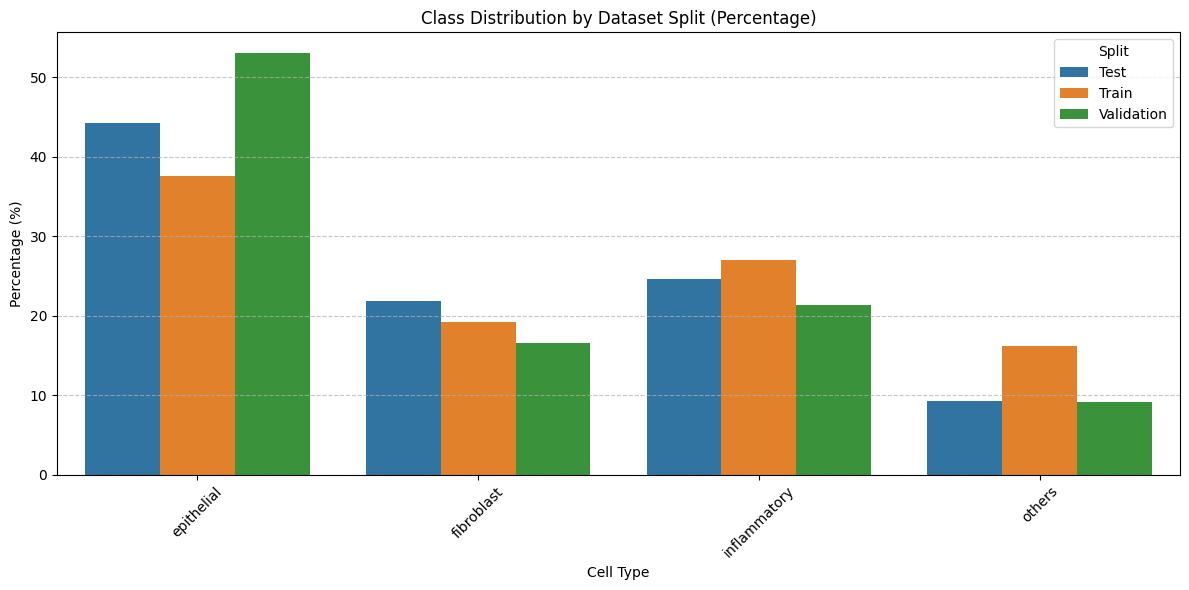

In [ ]:
# Combine them
combined = pd.concat([train_data, val_data, test_data], axis=0)

# Calculate percentage distribution
percent_df = (
    combined.groupby(['Split', 'cellTypeName'])
    .size()
    .reset_index(name='Count')
)

# Compute percentages within each split
percent_df['Percentage'] = percent_df.groupby('Split')['Count'].transform(lambda x: 100 * x / x.sum())

# Plot
plt.figure(figsize=(12, 6))
sns.barplot(data=percent_df, x='cellTypeName', y='Percentage', hue='Split')
plt.title("Class Distribution by Dataset Split (Percentage)")
plt.xlabel("Cell Type")
plt.ylabel("Percentage (%)")
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

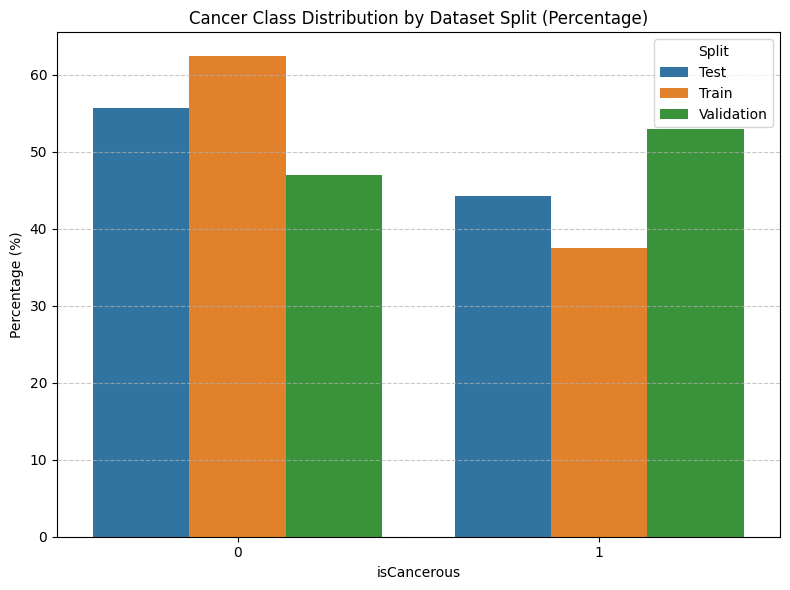

In [ ]:
# Combine splits
combined = pd.concat([train_data, val_data, test_data], axis=0)

# Calculate percentage distribution for isCancerous
percent_df = (
    combined.groupby(['Split', 'isCancerous'])
    .size()
    .reset_index(name='Count')
)

# Compute percentages within each Split (Train/Val/Test)
percent_df['Percentage'] = percent_df.groupby('Split')['Count'].transform(lambda x: 100 * x / x.sum())

# Plot
plt.figure(figsize=(8, 6))
sns.barplot(data=percent_df, x='isCancerous', y='Percentage', hue='Split')
plt.title("Cancer Class Distribution by Dataset Split (Percentage)")
plt.xlabel("isCancerous")
plt.ylabel("Percentage (%)")
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()



In [ ]:
# Relationship between cell type and isCancerous
pd.crosstab(main_data['cellTypeName'], main_data['isCancerous'])

isCancerous,0,1
cellTypeName,,
epithelial,0,4079
fibroblast,1888,0
inflammatory,2543,0
others,1386,0


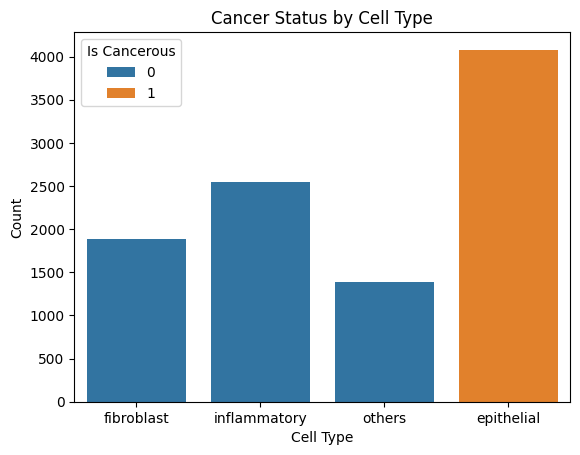

In [ ]:
# Plot relationship between cell type and isCancerous
sns.countplot(data=main_data, x='cellTypeName', hue='isCancerous')
plt.title('Cancer Status by Cell Type')
plt.xlabel('Cell Type')
plt.ylabel('Count')
plt.legend(title='Is Cancerous')
plt.show()


## **View images**

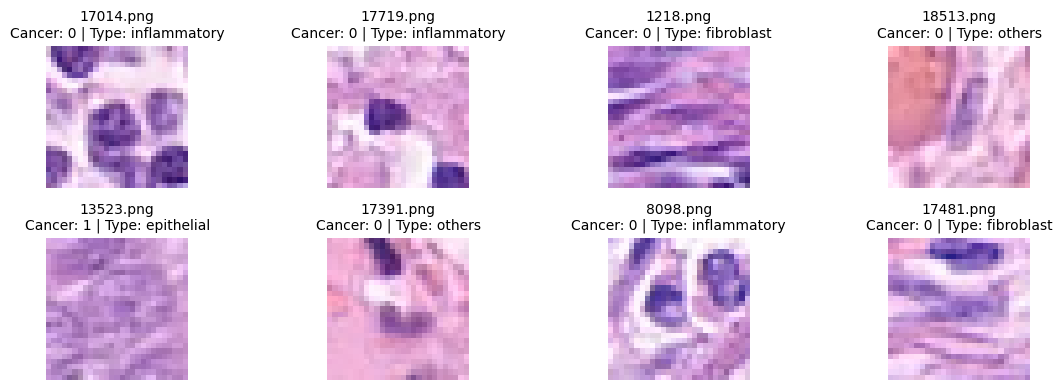

In [ ]:
# Randomly select and display 8 images
sampled_rows = train_data.sample(8, random_state=42).reset_index(drop=True)
fig, axes = plt.subplots(2, 4, figsize=(12, 4))
axes = axes.flatten()

for i in range(8):
    row = sampled_rows.iloc[i]
    image = imread(row['image_path'])

    axes[i].imshow(image)
    axes[i].axis('off')
    axes[i].set_title(f"{row['ImageName']}\nCancer: {row['isCancerous']} | Type: {row['cellTypeName']}", fontsize=10)

plt.tight_layout()
plt.show()


In [ ]:
# View Data for first record in training data
img = imread(train_data.iloc[0]['image_path'])

print("Data type:", img.dtype)
print("Min pixel value:", img.min())
print("Max pixel value:", img.max())

Data type: uint8
Min pixel value: 79
Max pixel value: 255


In [ ]:
# View shape and RGB values of first record in training data
img

array([[[226, 155, 182],
        [221, 148, 180],
        [201, 127, 164],
        ...,
        [235, 190, 225],
        [224, 177, 215],
        [222, 171, 214]],

       [[218, 151, 181],
        [220, 150, 181],
        [215, 141, 175],
        ...,
        [242, 203, 230],
        [232, 191, 224],
        [234, 188, 228]],

       [[207, 142, 182],
        [216, 146, 181],
        [224, 151, 181],
        ...,
        [249, 217, 236],
        [236, 201, 228],
        [235, 195, 231]],

       ...,

       [[221, 150, 194],
        [197, 135, 188],
        [168, 114, 177],
        ...,
        [189, 137, 187],
        [207, 158, 203],
        [214, 167, 209]],

       [[221, 151, 195],
        [212, 146, 196],
        [199, 139, 193],
        ...,
        [198, 146, 196],
        [233, 184, 229],
        [230, 185, 224]],

       [[204, 135, 181],
        [216, 148, 196],
        [204, 138, 187],
        ...,
        [207, 157, 206],
        [240, 190, 234],
        [251, 207, 245]]], dtype=uint8)

## **Observations**

* The main dataset contains 9896 records consisting of 60 patient records.

* There are two target variables - 'isCancerous' and 'cellType'.

* There are no missing labels.

* Images are 27x27 pixels.

## **Class Imbalance**

* 'isCancer' is mildly imbalanced: Approximately 42% labelled as cancerous and 58% labelled non-cancerous.

* 'cellType' is moderately imbalanced - with 41.2% of records labelled 'epithelial', 14% of records labelled as 'others' and 19.1% of records labelled as 'fibroblast'.

* There is a multiclass imbalance in that only epithelial cells are labelled cancerous. There are no examples of healthy epithelial cells.

* This may lead the models to identifying and learning epithelial cell features as cancerous features.

# **Pre-Processing**
* Several preprocessing techniques were applied to prepare the data and address known challenges such as the class imbalance identified during EDA and model generalisation.

* Image normalisation was performed by rescaling RGB pixel values from the range 0–255 to 0–1. This is standard practice in image classification tasks using neural networks, as it improves numerical stability and accelerates convergence during training (Kashyap, 2024).

* Oversampling was used to address class imbalance by upsampling minority classes using sklearn.utils.resample. This ensures that the model is exposed to a more balanced distribution of classes during training (Mujahid et al., 2024).

* Data augmentation was applied to the original dataset to introduce variability, using transformations such as flipping, rotation, and zooming. This helps reduce overfitting and encourages the model to learn more general features (Xu et al., 2023).

* Both oversampling and data augmentation were used in combination to expand the representation of minority classes and reduce overfitting at the same time, with the expectation we could get the benefits of both approaches.

In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Normalization
train_datagen = ImageDataGenerator(rescale=1./255, data_format='channels_last')
val_datagen = ImageDataGenerator(rescale=1./255, data_format='channels_last')
test_datagen = ImageDataGenerator(rescale=1./255, data_format='channels_last')

# Set batch size
batch_size_ic = 64 # Each group member developed the isCancer and cellType models independently, so we settled on different batch sizes through experimentation.
batch_size_ct = 128

## 'isCancer' Target


In [ ]:
# Convert images into numeric arrays
train_generator_IC = train_datagen.flow_from_dataframe(
        dataframe=train_data,
        directory=None,
        x_col="image_path",
        y_col="isCancerous",
        target_size=(27, 27),
        batch_size=batch_size_ic,
        shuffle=False, # Very important
        class_mode='categorical')

# Validation set for isCancerous

validation_generator_IC = val_datagen.flow_from_dataframe(
        dataframe=val_data,
        directory=None,
        x_col="image_path",
        y_col="isCancerous",
        target_size=(27, 27),
        batch_size=batch_size_ic,
        shuffle=False, # Very important
        class_mode='categorical')

# Test set for isCancerous

test_generator_IC = test_datagen.flow_from_dataframe(
        dataframe=test_data,
        directory=None,
        x_col="image_path",
        y_col="isCancerous",
        target_size=(27, 27),
        batch_size=batch_size_ic,
        shuffle=False, # Very important
        class_mode='categorical')

Found 6778 validated image filenames belonging to 2 classes.
Found 1738 validated image filenames belonging to 2 classes.
Found 1380 validated image filenames belonging to 2 classes.


## 'cellType' Target

In [ ]:
# Convert images into numeric arrays
train_generator_CT = train_datagen.flow_from_dataframe(
        dataframe=train_data,
        directory=None,
        x_col="image_path",
        y_col="cellType",
        target_size=(27, 27),
        batch_size=batch_size_ct,
        shuffle=False, # Very important
        class_mode='categorical')

# Validation set for cellType

validation_generator_CT = val_datagen.flow_from_dataframe(
        dataframe=val_data,
        directory=None,
        x_col="image_path",
        y_col="cellType",
        target_size=(27, 27),
        batch_size=batch_size_ct,
        shuffle=False, # Very important
        class_mode='categorical')
#Test set for cellType
test_generator_CT = test_datagen.flow_from_dataframe(
        dataframe=test_data,
        directory=None,
        x_col="image_path",
        y_col="cellType",
        target_size=(27, 27),
        batch_size=batch_size_ct,
        shuffle=False, # Very important
        class_mode='categorical')

Found 6778 validated image filenames belonging to 4 classes.
Found 1738 validated image filenames belonging to 4 classes.
Found 1380 validated image filenames belonging to 4 classes.


## **Oversampling**

* We applied oversampling to the training set for both target variables individually, as balancing both simultaneously is not feasible.

* To prevent batch homogeneity, we shuffled the oversampled data before training.

* We opted for a straightforward oversampling approach rather than a more complex method like SMOTE (Chawla et al., 2002), as we intended to introduce additional variability through data augmentation.

In [ ]:
from sklearn.utils import resample

# Create function for oversampling
def oversample_dataframe(df, label_col):
  # Determine the maximum class count to match for oversampling
    max_count = df[label_col].value_counts().max()

    balanced_dfs = []
    # Loop through each class group in the dataset
    for class_label, group_df in df.groupby(label_col):
        # Resample the current class to match the max_count (with replacement)
        resampled_group = resample(
            group_df,
            replace=True,  #Sample with replacement
            n_samples=max_count, # Match the size of the largest class
            random_state=seed # Ensure reproducibility
        )
        balanced_dfs.append(resampled_group)
     # Concatenate all oversampled class groups into a single balanced DataFrame
    df_oversampled = pd.concat(balanced_dfs).reset_index(drop=True)
    return df_oversampled

In [ ]:
# Oversample for 'isCancer' target imbalance
train_oversampled_IC = oversample_dataframe(train_data, 'isCancerous').sample(frac=1, random_state=seed).reset_index(drop=True)

# Oversample for 'cellType' target imbalance
train_oversampled_CT = oversample_dataframe(train_data, 'cellType').sample(frac=1, random_state=seed).reset_index(drop=True)

In [ ]:
# Inspect oversampled dataframe (isCancerous)
train_oversampled_IC.head()

,InstanceID,patientID,ImageName,cellTypeName,cellType,isCancerous,image_path,Split
0,11941,31,11941.png,epithelial,2,1,./patch_images/11941.png,Train
1,8260,40,8260.png,epithelial,2,1,./patch_images/8260.png,Train
2,21184,57,21184.png,inflammatory,1,0,./patch_images/21184.png,Train
3,13922,54,13922.png,epithelial,2,1,./patch_images/13922.png,Train
4,13730,54,13730.png,others,3,0,./patch_images/13730.png,Train


In [ ]:
# Inspect balance in newly created oversampled 'isCancerous' data
train_oversampled_IC['isCancerous'].value_counts()

,count
isCancerous,
1,4231
0,4231


In [ ]:
# Inspect balance in newly created oversampled 'cellType' data
train_oversampled_CT['cellType'].value_counts()

,count
cellType,
1,2547
2,2547
0,2547
3,2547


### Oversampled 'Is-Cancer'

In [ ]:
# Generate numeric arrays for oversampled subset
train_generator_IC_os = train_datagen.flow_from_dataframe(
        dataframe=train_oversampled_IC,
        directory=None,
        x_col="image_path",
        y_col="isCancerous",
        target_size=(27, 27),
        batch_size=batch_size_ic,
        shuffle=False, # Very important
        class_mode='categorical')

Found 8462 validated image filenames belonging to 2 classes.


### Oversampled Cell Type

In [ ]:
# Generate numeric arrays for oversampled subset
train_generator_CT_os = train_datagen.flow_from_dataframe(
        dataframe=train_oversampled_CT,
        directory=None,
        x_col="image_path",
        y_col="cellType",
        target_size=(27, 27),
        batch_size=batch_size_ct,
        shuffle=False, # Very important
        class_mode='categorical')

Found 10188 validated image filenames belonging to 4 classes.


## **Data Augmentation**

* Data augmentation is applied to increase data variability and mitigate early overfitting during training.

* Augmentation was applied to both the original and oversampled datasets for each target variable, with the aim of reducing the heightened risk of overfitting introduced by oversampling.

In [ ]:
# Create image augmentation variable
train_datagen_da = ImageDataGenerator(
    rescale=1./255,
    rotation_range=15, #Image rotation
    width_shift_range=0.1, #Shifts
    height_shift_range=0.1,
    horizontal_flip=True, #Flips
    zoom_range=0.1, #Zoom
    fill_mode='nearest'
)

### Is Cancer

In [ ]:
# Augment 'isCancerous' subset
train_generator_IC_da = train_datagen_da.flow_from_dataframe(
        dataframe=train_data,
        directory=None,
        x_col="image_path",
        y_col="isCancerous",
        target_size=(27, 27),
        batch_size=batch_size_ic,
        shuffle=False, # Very important
        class_mode='categorical')

# Oversampled and Augmented 'isCancerous' subset
train_generator_IC_os_da = train_datagen_da.flow_from_dataframe(
        dataframe=train_oversampled_IC,
        directory=None,
        x_col="image_path",
        y_col="isCancerous",
        target_size=(27, 27),
        batch_size=batch_size_ic,
        shuffle=False, # Very important
        class_mode='categorical')

Found 6778 validated image filenames belonging to 2 classes.
Found 8462 validated image filenames belonging to 2 classes.


### Cell Type

In [ ]:
# Augment 'cellType' subset
train_generator_CT_da = train_datagen_da.flow_from_dataframe(
        dataframe=train_data,
        directory=None,
        x_col="image_path",
        y_col="cellType",
        target_size=(27, 27),
        batch_size=batch_size_ct,
        shuffle=False, # Very important
        class_mode='categorical')

# Oversampled and Augmented 'cellType' subset
train_generator_CT_os_da = train_datagen_da.flow_from_dataframe(
        dataframe=train_oversampled_CT,
        directory=None,
        x_col="image_path",
        y_col="cellType",
        target_size=(27, 27),
        batch_size=batch_size_ct,
        shuffle=False, # Very important
        class_mode='categorical')

Found 6778 validated image filenames belonging to 4 classes.
Found 10188 validated image filenames belonging to 4 classes.


# **Model Optimization**

This section outlines the strategies we applied to optimise model performance before beginning the modelling phase in the next section. It includes:

* The performance metrics selected for evaluation
* Methods used to detect and reduce overfitting
* The validation and hyperparameter tuning strategy
* Our use of early stopping and learning rate adjustment
* Utility functions defined for use during model training and evaluation

## **Determine Performance Metrics**

* Weighted F1 score is the primary performance metric, chosen due to class imbalance and its use in related literature for easier comparison (Mosquera et al., 2024).

* As the harmonic mean of precision and recall, it balances false positives and false negatives, making it well-suited for imbalanced datasets (Mosquera et al., 2024).

* This metric was also used for early stopping and monitored in the validation curve, as we chose to maximise this metric.

* Validation Loss is monitored during training using the validation curves below.

* In the cancer detection task, recall is critical due to the high cost of false negatives, as it measures the model’s ability to identify all actual cancer cases.

* Test data is reserved for evaluating final models only, ensuring an unbiased assessment of generalisation performance.

### Learning Curve Function

In [ ]:
"""
This function plots the validation curve for both then loss and a second metric of our choice, which in this case is weighted F1.

"""

def plot_learning_curve(train_loss, val_loss, train_metric, val_metric, metric_name='Accuracy'): #Default is accuracy but is changed to weighted F1 in this project.
    plt.figure(figsize=(10,5))
    # Plots validation/training loss subplot
    plt.subplot(1,2,1)
    plt.plot(train_loss, 'r--')
    plt.plot(val_loss, 'b--')
    plt.xlabel("epochs")
    plt.ylabel("Loss")
    plt.legend(['train', 'val'], loc='upper left')
    #Plots validation/training chosen metric subplot
    plt.subplot(1,2,2)
    plt.plot(train_metric, 'r--')
    plt.plot(val_metric, 'b--')
    plt.xlabel("epochs")
    plt.ylabel(metric_name)
    plt.legend(['train', 'val'], loc='upper left')

    plt.show()

## Overfitting

To reduce overfitting and improve generalisation, several regularisation techniques were applied:

* Early stopping halted training when validation F1 stopped improving, preventing overfitting to noise.

* Data augmentation introduced variation (e.g. rotation, flipping) to reduce reliance on specific features.

* L2 regularisation penalised large weights, encouraging simpler, more generalisable models.

* Dropout randomly deactivated neurons during training, reducing co-adaptation and improving robustness.


### Early Stopping

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping

#Define early stopping
early_stop = tf.keras.callbacks.EarlyStopping(
            monitor='val_weighted_f1', # Metric to consider early stopping
            patience=30,               # Number of epochs to wait until early stopping occurs
            restore_best_weights=True, # Saves weights from end of best epoch
            mode='max',                # Maximizing weighted f1
            verbose=1
        )

### Adjust Learning Rate

In [ ]:
# Dynamic learning rate
lr_callback = tf.keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,           # Reduces learning rate by a factor of 0.5 (half)
    patience=10,          # Allows training to continue for 10 epochs before learning rate is reduced
    min_lr=1e-6
)

### Classification Report

In [ ]:
# Create function to generate classification report on trained models.
from sklearn.metrics import classification_report

def get_classification_report(model, generator, target_names=None):

    #Predict class probabilities
    y_probs = model.predict(generator)

    #Predicted class indices
    y_pred = np.argmax(y_probs, axis=1)

    #True class indices
    y_true = generator.classes

    #Classification report
    report = classification_report(y_true, y_pred, target_names=target_names, digits=3)

    return report


### Custom Grid Search for Hold-Out Validation


**Validation Set**.    
* A custom grid search function was built to evaluate a wide range of hyperparameter combinations.

* Each model was trained with early stopping monitored using validation weighted F1.

* The best model was selected based on peak validation F1 score, ensuring optimal performance before testing.

* Validation curves were plotted to visualise training dynamics for the best-performing model.

In [ ]:
# Create function to test models on wide range of parameters

from sklearn.model_selection import ParameterGrid

def grid_search(model_builder_fn, param_grid_dict, train_data, val_data, num_classes):
    best_model = None
    best_score = -1
    best_params = None
    best_history = None

    # Convert the dict to a list of param combinations
    param_grid = list(ParameterGrid(param_grid_dict))

    for params in param_grid:
        print(f"Trying params: {params}")
        # Build a new model instance with the current set of parameters
        model = model_builder_fn(num_classes=num_classes, **params)

        # Set up early stopping to prevent overfitting and save best weights
        early_stop = tf.keras.callbacks.EarlyStopping(
            monitor='val_weighted_f1',
            patience=30,
            restore_best_weights=True,
            mode='max',
            verbose=0
        )

        # Compile the model with weighted F1 as the key performance metric
        model.compile(
            optimizer='adam',
            loss='categorical_crossentropy',
            metrics=[tf.keras.metrics.F1Score(average='weighted', name='weighted_f1')]
        )
        # Train the model with validation monitoring and learning rate reduction
        history = model.fit(
            train_data,
            validation_data=val_data,
            epochs=100,
            callbacks=[early_stop,lr_callback],
            verbose=0
        )
        # Track the best validation F1 score and corresponding model
        best_val_f1 = max(history.history['val_weighted_f1'])

        if best_val_f1 > best_score:
            best_score = best_val_f1
            best_model = model
            best_history = history
            best_params = params
    # Plot the training and validation curves for the best model
    plot_learning_curve(best_history.history['loss'], best_history.history['val_loss'],
                    best_history.history['weighted_f1'], best_history.history['val_weighted_f1'],
                    metric_name='weighted_f1_score')
    print(f"Best validation weighted F1: {best_score:.4f}")
    print(f"Best parameters: {best_params}")
    return best_model


# **Modelling**

In [ ]:
# Global variables
INPUT_DIM = (27, 27, 3)
OUTPUT_CLASSES_IC = 2
OUTPUT_CLASSES_CT = 4

## Base Model Architecture

* CNN-MLP Architecture is chosen as it known to be best at extracting spatial features from images (Alzubaidi et al., 2021).

* For the hidden layers the selected activation function for the base model is Rectified Linear Unit (ReLU), as it is computationally efficient due to setting all negative activations to 0 and mitigates the vanishing gradient problem. Additionally it supports hierachical feature learning (Alzubaidi et al., 2021).

* One convolutional block with two convolutions consisting of 3x3 kernels and 32 filters.

* MaxPooling is used to reduce spatial dimensions.

* This is fed into an MLP block where the 3D feature maps are 'flattened' to a 1D vector to feed into the dense layers.

* Dense output layer has two class outputs, with a softmax activation function.

* The base model has no regularization and padding is set to 'same'.

* These parameters were selected based on the training sample size, the image dimensions and archictures used for similar prediction tasks.

In [ ]:
# Basline model builder
from tensorflow.keras import layers, regularizers

def build_cnn_mlp(num_classes, activation='relu', padding='same', l2_lambda=0): #No default regularisation

    model = tf.keras.Sequential([
        # 2 conv laters.
        tf.keras.layers.Conv2D(32, (3, 3), activation=activation, padding=padding, kernel_regularizer=regularizers.l2(l2_lambda), input_shape=INPUT_DIM),
        tf.keras.layers.Conv2D(32, (3, 3), activation=activation, padding=padding, kernel_regularizer=regularizers.l2(l2_lambda)),
        tf.keras.layers.MaxPooling2D((2, 2)), #Max pooling to reduce image dimensions
        #MLP Layer
        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(128, activation=activation),
        tf.keras.layers.Dense(num_classes, activation='softmax') #Use softmax on output
    ])

    return model

## Base Model: 'isCancerous'

Epoch 38: early stopping
Restoring model weights from the end of the best epoch: 8.


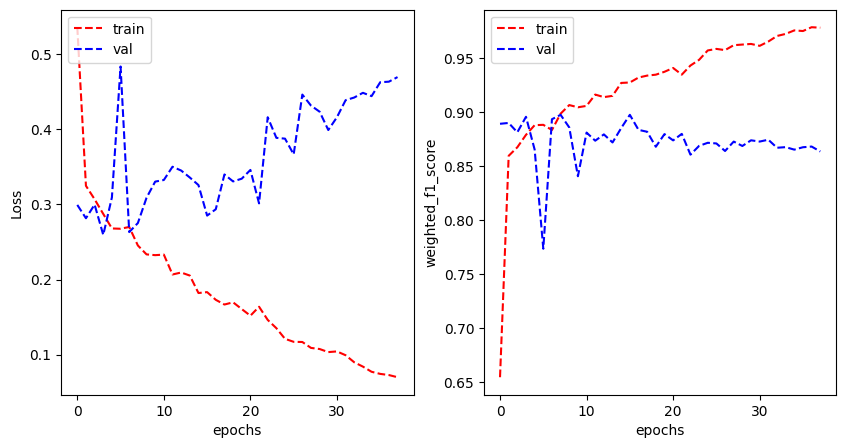

28/28 ━━━━━━━━━━━━━━━━━━━━ 1s 34ms/step
Classification Report:
              precision    recall  f1-score   support

           0      0.869     0.922     0.894       817
           1      0.927     0.876     0.901       921

    accuracy                          0.898      1738
   macro avg      0.898     0.899     0.897      1738
weighted avg      0.899     0.898     0.898      1738



In [ ]:
# Create instance of base model
baseline_model_ic = build_cnn_mlp(num_classes=OUTPUT_CLASSES_IC)

# Compile base model
baseline_model_ic.compile(optimizer='adam',
                          loss=tf.keras.losses.CategoricalCrossentropy(from_logits=False),
                          metrics=[tf.keras.metrics.F1Score(average='weighted',name='weighted_f1')])

# Fit base model to training data
baseline_model_ic_history = baseline_model_ic.fit(train_generator_IC,
                                                  validation_data = validation_generator_IC,
                                                  epochs=100,
                                                  verbose=0,
                                                  callbacks=[early_stop,lr_callback])
# Plot learning curve
plot_learning_curve(baseline_model_ic_history.history['loss'],
                    baseline_model_ic_history.history['val_loss'],
                    baseline_model_ic_history.history['weighted_f1'],
                    baseline_model_ic_history.history['val_weighted_f1'],
                    metric_name='weighted_f1_score')

#Get classificication report on validation data
cr = get_classification_report(baseline_model_ic, validation_generator_IC)
print("Classification Report:")
print(cr)

* The baseline model performed well, now will test using oversampled and augmented data

## Model Using Oversampling: 'isCancerous'

Epoch 33: early stopping
Restoring model weights from the end of the best epoch: 3.


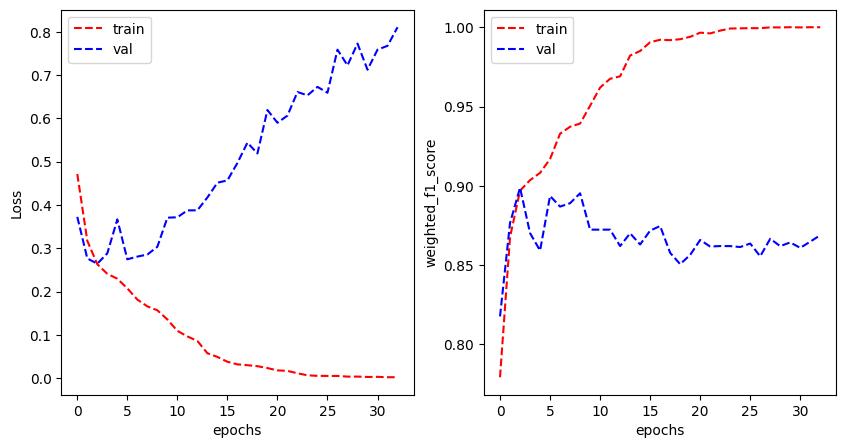

28/28 ━━━━━━━━━━━━━━━━━━━━ 2s 44ms/step
Classification Report:
              precision    recall  f1-score   support

           0      0.877     0.913     0.894       817
           1      0.920     0.886     0.903       921

    accuracy                          0.899      1738
   macro avg      0.898     0.900     0.899      1738
weighted avg      0.900     0.899     0.899      1738



In [ ]:
# Create instance of base model
os_model_ic = build_cnn_mlp(num_classes=OUTPUT_CLASSES_IC)

# Compile base model
os_model_ic.compile(optimizer='adam',
                    loss=tf.keras.losses.CategoricalCrossentropy(from_logits=False),
                    metrics=[tf.keras.metrics.F1Score(average='weighted',name='weighted_f1')])

# Fit base model to training data
os_model_ic_history = os_model_ic.fit(train_generator_IC_os,
                                      validation_data = validation_generator_IC,
                                      epochs=100,
                                      verbose=0,
                                      callbacks=[early_stop,lr_callback])
# Plot learning curve
plot_learning_curve(os_model_ic_history.history['loss'],
                    os_model_ic_history.history['val_loss'],
                    os_model_ic_history.history['weighted_f1'],
                    os_model_ic_history.history['val_weighted_f1'],
                    metric_name='weighted_f1_score')

#Get classificication report on validation data
cr = get_classification_report(os_model_ic, validation_generator_IC)
print("Classification Report:")
print(cr)

* A minor improvement in the weighted F1 score, however there is obvious overfitting to the training data after epoch 5.

## Model Using Data Augmentation: 'isCancerous'

Epoch 88: early stopping
Restoring model weights from the end of the best epoch: 58.


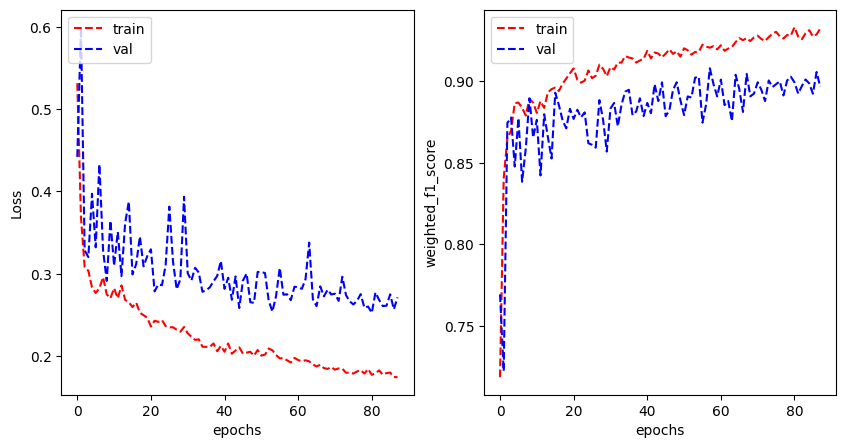

28/28 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step
Classification Report:
              precision    recall  f1-score   support

           0      0.865     0.953     0.907       817
           1      0.955     0.868     0.909       921

    accuracy                          0.908      1738
   macro avg      0.910     0.911     0.908      1738
weighted avg      0.912     0.908     0.908      1738



In [ ]:
# Create instance of base model
da_model_ic = build_cnn_mlp(num_classes=OUTPUT_CLASSES_IC)

# Compile base model
da_model_ic.compile(optimizer='adam',
                    loss=tf.keras.losses.CategoricalCrossentropy(from_logits=False),
                    metrics=[tf.keras.metrics.F1Score(average='weighted',name='weighted_f1')])

# Fit base model to training data
da_model_ic_history = da_model_ic.fit(train_generator_IC_da,
                                      validation_data = validation_generator_IC,
                                      epochs=100,
                                      verbose=0,
                                      callbacks=[early_stop,lr_callback])

plot_learning_curve(da_model_ic_history.history['loss'],
                    da_model_ic_history.history['val_loss'],
                    da_model_ic_history.history['weighted_f1'],
                    da_model_ic_history.history['val_weighted_f1'],
                    metric_name='weighted_f1_score')

#Get classificication report on validation data
cr = get_classification_report(da_model_ic, validation_generator_IC)
print("Classification Report:")
print(cr)

* Augmented data has yeilded the best results, with mild overfitting to training data and a weighted F1 of 0.908

 ## **Final Model:** 'isCancerous'
The final model balances complexity and performance. Additional layers beyond this point showed no meaningful gains.

Key features:

* One extra convolutional layer added
* First layer uses a 5×5 kernel
* 20% dropout applied to the third convolutional layer
* Average pooling replaces flattening
* leaky_relu selected as the activation function based on test results
* Padding set to 'same' due to small image size
* L2 regularisation (λ = 0.01) included to reduce overfitting
* Using Augmented data yeilded the best results

In [ ]:
def build_cnn_mlp_ic_BEST(num_classes=OUTPUT_CLASSES_IC, activation='leaky_relu', padding='same', l2_lambda=0.01): # 0 means no regularisation

    model = tf.keras.Sequential([
        # Conv layers with maxpooling
        tf.keras.layers.Conv2D(32, (5, 5), activation=activation, padding=padding, kernel_regularizer=regularizers.l2(l2_lambda), input_shape=INPUT_DIM),
        tf.keras.layers.Conv2D(32, (3, 3), activation=activation, padding=padding, kernel_regularizer=regularizers.l2(l2_lambda)),
        tf.keras.layers.MaxPooling2D((2, 2)),
        # Third conv layer with dropout
        tf.keras.layers.Conv2D(64, (3, 3), activation=activation, padding=padding, kernel_regularizer=regularizers.l2(l2_lambda)),
        tf.keras.layers.Dropout(0.2),
        #MLP Layer with average pooling
        tf.keras.layers.GlobalAveragePooling2D(),
        tf.keras.layers.Dense(128, activation=activation),
        tf.keras.layers.Dense(num_classes, activation='softmax')
    ])

    return model

* **Note that this paramater grid is only a representative sample of the paramaters we tried. We tried many more values, but wanted to keep the number of combinations to relatively low.**

Trying params: {'activation': 'gelu', 'l2_lambda': 0.0001, 'padding': 'same'}


Trying params: {'activation': 'gelu', 'l2_lambda': 0.0001, 'padding': 'valid'}
Trying params: {'activation': 'gelu', 'l2_lambda': 0.001, 'padding': 'same'}
Trying params: {'activation': 'gelu', 'l2_lambda': 0.001, 'padding': 'valid'}
Trying params: {'activation': 'gelu', 'l2_lambda': 0.01, 'padding': 'same'}
Trying params: {'activation': 'gelu', 'l2_lambda': 0.01, 'padding': 'valid'}
Trying params: {'activation': 'relu', 'l2_lambda': 0.0001, 'padding': 'same'}
Trying params: {'activation': 'relu', 'l2_lambda': 0.0001, 'padding': 'valid'}
Trying params: {'activation': 'relu', 'l2_lambda': 0.001, 'padding': 'same'}
Trying params: {'activation': 'relu', 'l2_lambda': 0.001, 'padding': 'valid'}
Trying params: {'activation': 'relu', 'l2_lambda': 0.01, 'padding': 'same'}
Trying params: {'activation': 'relu', 'l2_lambda': 0.01, 'padding': 'valid'}
Trying params: {'activation': 'leaky_relu', 'l2_lambda': 0.0001, 'padding': 'same'}
Trying params: {'activation': 'leaky_relu', 'l2_lambda': 0.0001,

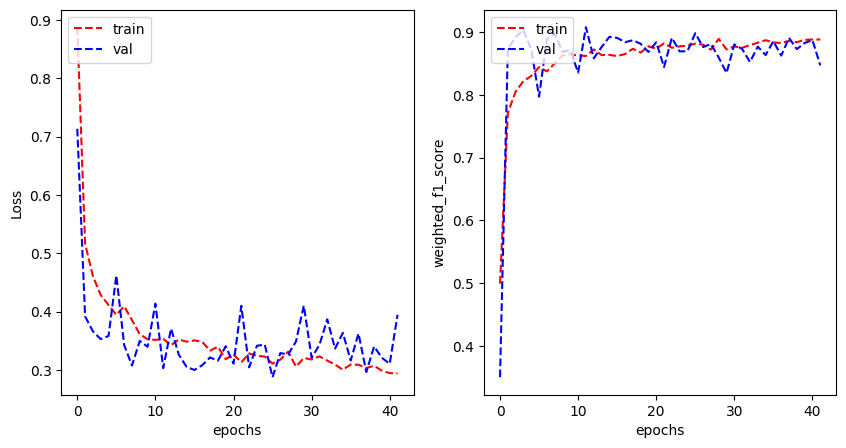

Best validation weighted F1: 0.9078
Best parameters: {'activation': 'relu', 'l2_lambda': 0.01, 'padding': 'same'}
28/28 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step
Classification Report:
              precision    recall  f1-score   support

           0      0.922     0.879     0.900       817
           1      0.897     0.934     0.915       921

    accuracy                          0.908      1738
   macro avg      0.909     0.906     0.907      1738
weighted avg      0.908     0.908     0.908      1738



In [ ]:
param_grid = { #Parameter grid with hyper-parameter values (not exhaustive)
    'activation': ['gelu', 'relu', 'leaky_relu'],
    'padding': ['same', 'valid'],
    'l2_lambda': [0.0001, 0.001, 0.01]
}

#Use the parameter grid to obtain the best model with the optimal combination of hyperparameters
best_model_IC = grid_search(
    model_builder_fn=build_cnn_mlp_ic_BEST,
    param_grid_dict=param_grid,
    train_data=train_generator_IC_da,
    val_data=validation_generator_IC,
    num_classes=OUTPUT_CLASSES_IC
)
#Classification report on validation set
cr = get_classification_report(best_model_IC, validation_generator_IC)
print("Classification Report:")
print(cr)

* Applying best model to unseen test data. Weighted F1 = 0.865

In [ ]:
# Classification report on the test data
cr = get_classification_report(best_model_IC, test_generator_IC)
print("Classification Report:")
print(cr)

 9/22 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step

22/22 ━━━━━━━━━━━━━━━━━━━━ 1s 35ms/step
Classification Report:
              precision    recall  f1-score   support

           0      0.882     0.874     0.878       769
           1      0.843     0.853     0.848       611

    accuracy                          0.864      1380
   macro avg      0.862     0.863     0.863      1380
weighted avg      0.865     0.864     0.865      1380



# Base Model: 'cellType' Model

* The baseline architecture was first used to predict cellType, achieving a weighted F1-score of 0.74, which served as a reasonable starting point.

Epoch 46: early stopping
Restoring model weights from the end of the best epoch: 16.


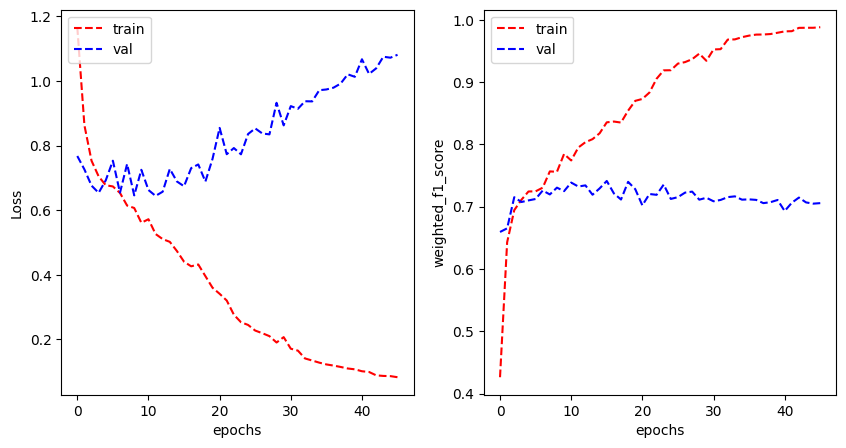

14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 40ms/step
Classification Report:
              precision    recall  f1-score   support

           0      0.668     0.517     0.583       288
           1      0.603     0.830     0.698       371
           2      0.878     0.890     0.884       921
           3      0.486     0.215     0.298       158

    accuracy                          0.754      1738
   macro avg      0.659     0.613     0.616      1738
weighted avg      0.749     0.754     0.741      1738



In [ ]:
#Build model with given parameters
baseline_model_ct = build_cnn_mlp(num_classes=OUTPUT_CLASSES_CT, activation='relu', padding='same', l2_lambda=0)
baseline_model_ct.compile(optimizer='adam', loss=tf.keras.losses.CategoricalCrossentropy(from_logits=False), metrics=[tf.keras.metrics.F1Score(average='weighted',name='weighted_f1')])

baseline_model_ct_history = baseline_model_ct.fit(train_generator_CT, validation_data = validation_generator_CT, epochs=100,callbacks=[early_stop,lr_callback], verbose=0)

#Plot Learning Curve
plot_learning_curve(baseline_model_ct_history.history['loss'], baseline_model_ct_history.history['val_loss'],
                    baseline_model_ct_history.history['weighted_f1'], baseline_model_ct_history.history['val_weighted_f1'],
                    metric_name='weighted_f1_score')

# Print classification report for validation set
cr = get_classification_report(baseline_model_ct, validation_generator_CT)
print("Classification Report:")
print(cr)


* The improved architecture for the cellType task consistently outperformed the baseline across all experiments.

* Various alternatives (e.g. batch normalisation, average pooling) were tested, but excluded when they offered no performance gains, in line with the principle of simplicity.

* The deeper architecture provided greater learning capacity, and with overfitting controlled, delivered stronger results than the simpler baseline.

* Although only one baseline result is shown, all experiments (e.g. oversampling, augmentation, tuning) were conducted on both models.

* To reduce redundancy, only the improved model’s results are included, as it performed best in every configuration.



In [ ]:
from tensorflow.keras import layers, regularizers
def build_cnn_mlp_CT(num_classes, activation='relu', padding='same', l2_lambda=0,dropout_factor = 0):

    model = tf.keras.Sequential([
        layers.Input(shape=INPUT_DIM),
        # 2 conv layers with no-pooling (because it would be too much)
        layers.Conv2D(32, (3, 3), activation=activation, padding=padding, kernel_regularizer=regularizers.l2(l2_lambda)),
        layers.Conv2D(32, (3, 3), activation=activation, padding=padding, kernel_regularizer=regularizers.l2(l2_lambda)),


        #2 conv layers with max pooling
        layers.Conv2D(64, (3, 3), activation=activation, padding=padding, kernel_regularizer=regularizers.l2(l2_lambda)),
        layers.Conv2D(64, (3, 3), activation=activation, padding=padding, kernel_regularizer=regularizers.l2(l2_lambda)),
        layers.MaxPooling2D((2, 2)),
        #another 2 conv layers with max pooling
        layers.Conv2D(128, (3, 3), activation=activation, padding=padding, kernel_regularizer=regularizers.l2(l2_lambda)),
        layers.Conv2D(128, (3, 3), activation=activation, padding=padding, kernel_regularizer=regularizers.l2(l2_lambda)),
        layers.MaxPooling2D((2, 2)),

        #MLP layer
        layers.Flatten(),
        layers.Dense(256, activation=activation),
        layers.Dropout(dropout_factor), #Added dropout with tunable value

        layers.Dense(num_classes, activation='softmax')
    ])

    return model

### Improved Model

* Peformance of the improved architecture on the baseline training data and hyper-parameters.

Epoch 42: early stopping
Restoring model weights from the end of the best epoch: 12.


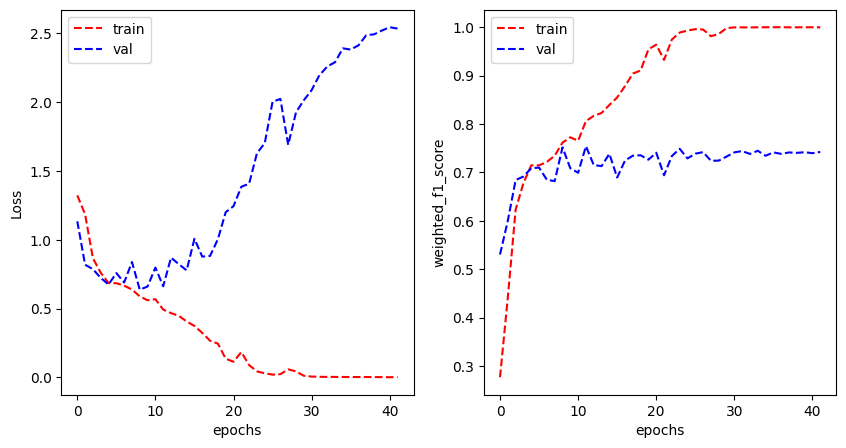

14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 58ms/step
Classification Report:
              precision    recall  f1-score   support

           0      0.743     0.531     0.619       288
           1      0.612     0.871     0.719       371
           2      0.909     0.876     0.892       921
           3      0.328     0.241     0.277       158

    accuracy                          0.760      1738
   macro avg      0.648     0.630     0.627      1738
weighted avg      0.765     0.760     0.754      1738



In [ ]:
#Build model with given parameters
baseline_model_ct = build_cnn_mlp_CT(num_classes=OUTPUT_CLASSES_CT, activation='relu', padding='same', l2_lambda=0,dropout_factor = 0)
baseline_model_ct.compile(optimizer='adam', loss=tf.keras.losses.CategoricalCrossentropy(from_logits=False), metrics=[tf.keras.metrics.F1Score(average='weighted',name='weighted_f1')])

baseline_model_ct_history = baseline_model_ct.fit(train_generator_CT, validation_data = validation_generator_CT, epochs=100,callbacks=[early_stop,lr_callback], verbose=0)

#Plot Learning Curve
plot_learning_curve(baseline_model_ct_history.history['loss'], baseline_model_ct_history.history['val_loss'],
                    baseline_model_ct_history.history['weighted_f1'], baseline_model_ct_history.history['val_weighted_f1'],
                    metric_name='weighted_f1_score')

# Print classification report for validation set
cr = get_classification_report(baseline_model_ct, validation_generator_CT)
print("Classification Report:")
print(cr)


### Oversampling

* Performance of the improved architecture on the oversampled data.

Epoch 73: early stopping
Restoring model weights from the end of the best epoch: 43.


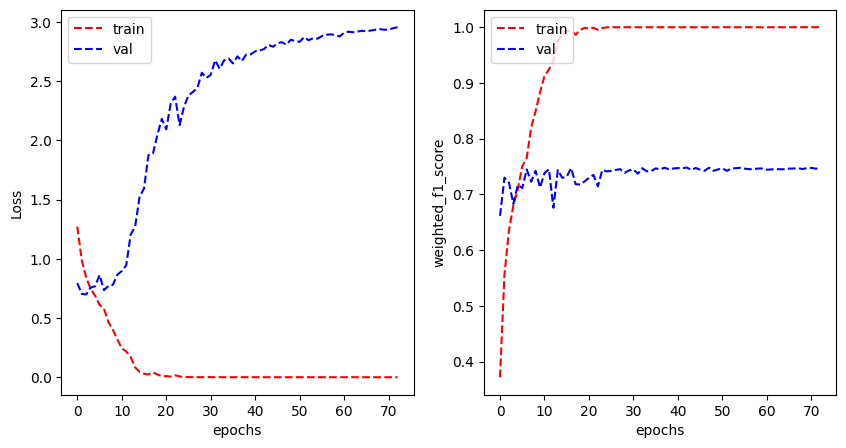

14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 52ms/step
Classification Report:
              precision    recall  f1-score   support

           0      0.628     0.615     0.621       288
           1      0.632     0.709     0.668       371
           2      0.911     0.863     0.886       921
           3      0.353     0.373     0.363       158

    accuracy                          0.745      1738
   macro avg      0.631     0.640     0.635      1738
weighted avg      0.754     0.745     0.748      1738



In [ ]:
#Build model with given parameters
oversample_model_ct = build_cnn_mlp_CT(num_classes=OUTPUT_CLASSES_CT, activation='relu', padding='same', l2_lambda=0, dropout_factor = 0)
oversample_model_ct.compile(optimizer='adam', loss=tf.keras.losses.CategoricalCrossentropy(from_logits=False), metrics=[tf.keras.metrics.F1Score(average='weighted',name='weighted_f1')])

oversample_model_ct_history = oversample_model_ct.fit(train_generator_CT_os, validation_data = validation_generator_CT, epochs=100,callbacks=[early_stop,lr_callback], verbose=0)
#Plot Learning Curve
plot_learning_curve(oversample_model_ct_history.history['loss'], oversample_model_ct_history.history['val_loss'],
                    oversample_model_ct_history.history['weighted_f1'], oversample_model_ct_history.history['val_weighted_f1'],
                    metric_name='weighted_f1_score')

# Print classification report for validation set
cr = get_classification_report(oversample_model_ct, validation_generator_CT)
print("Classification Report:")
print(cr)

### Data Augmentation

* Performance of the improved architecture on the augmented data

Epoch 80: early stopping
Restoring model weights from the end of the best epoch: 50.


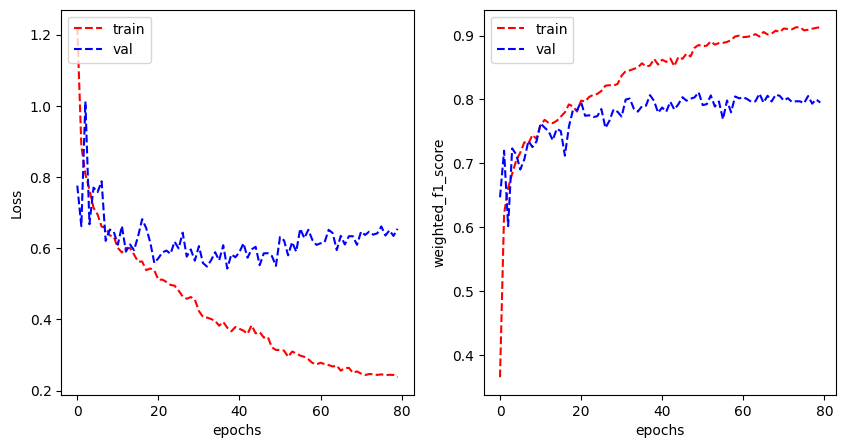

14/14 ━━━━━━━━━━━━━━━━━━━━ 2s 80ms/step
Classification Report:
              precision    recall  f1-score   support

           0      0.746     0.743     0.744       288
           1      0.717     0.814     0.763       371
           2      0.918     0.907     0.912       921
           3      0.533     0.405     0.460       158

    accuracy                          0.814      1738
   macro avg      0.728     0.717     0.720      1738
weighted avg      0.811     0.814     0.811      1738



In [ ]:
#Build model with given parameters
da_model_ct = build_cnn_mlp_CT(num_classes=OUTPUT_CLASSES_CT, activation='relu', padding='same', l2_lambda=0,dropout_factor = 0)
da_model_ct.compile(optimizer='adam', loss=tf.keras.losses.CategoricalCrossentropy(from_logits=False), metrics=[tf.keras.metrics.F1Score(average='weighted',name='weighted_f1')])

da_model_ct_history = da_model_ct.fit(train_generator_CT_da, validation_data = validation_generator_CT, epochs=200,callbacks=[early_stop,lr_callback], verbose=0)
#Plot Learning Curve
plot_learning_curve(da_model_ct_history.history['loss'], da_model_ct_history.history['val_loss'],
                    da_model_ct_history.history['weighted_f1'], da_model_ct_history.history['val_weighted_f1'],
                    metric_name='weighted_f1_score')

# Print classification report for validation set
cr = get_classification_report(da_model_ct, validation_generator_CT)
print("Classification Report:")
print(cr)

### Oversampling + Data Augmentation

* Performance of the improved model on Oversampled + Augmented Data

Epoch 65: early stopping
Restoring model weights from the end of the best epoch: 35.


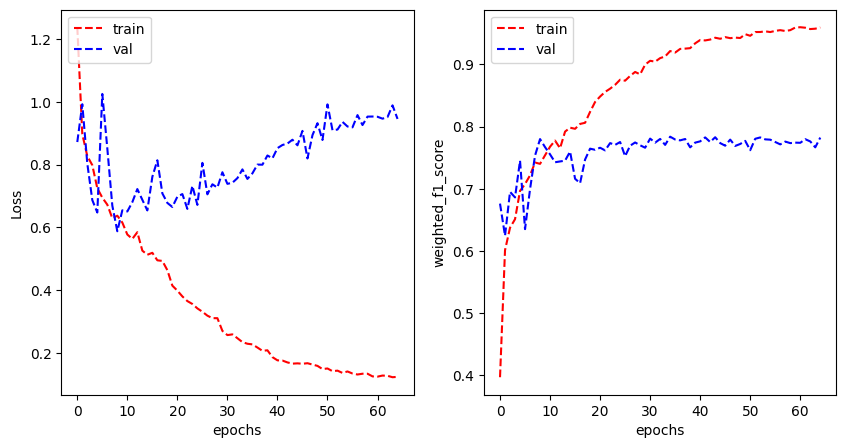

14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 59ms/step
Classification Report:
              precision    recall  f1-score   support

           0      0.709     0.743     0.725       288
           1      0.644     0.790     0.709       371
           2      0.934     0.847     0.888       921
           3      0.473     0.437     0.454       158

    accuracy                          0.780      1738
   macro avg      0.690     0.704     0.694      1738
weighted avg      0.793     0.780     0.784      1738



In [ ]:
#Build model with given parameters
da_model_ct = build_cnn_mlp_CT(num_classes=OUTPUT_CLASSES_CT, activation='relu', padding='same', l2_lambda=0,dropout_factor = 0)
da_model_ct.compile(optimizer='adam', loss=tf.keras.losses.CategoricalCrossentropy(from_logits=False), metrics=[tf.keras.metrics.F1Score(average='weighted',name='weighted_f1')])

da_model_ct_history = da_model_ct.fit(train_generator_CT_os_da, validation_data = validation_generator_CT, epochs=100,callbacks=[early_stop,lr_callback], verbose=0)
#Plot Learning Curve
plot_learning_curve(da_model_ct_history.history['loss'], da_model_ct_history.history['val_loss'],
                    da_model_ct_history.history['weighted_f1'], da_model_ct_history.history['val_weighted_f1'],
                    metric_name='weighted_f1_score')

# Print classification report for validation set
cr = get_classification_report(da_model_ct, validation_generator_CT)
print("Classification Report:")
print(cr)

### Hyperparameter Tuning

* In this section I use hyperparameter tuning on the improved model on the best data (which was the augmented data with no oversampling).

* **Note that this paramater grid is only a representative sample of the paramaters we tried. We tried many more values, but wanted to keep the number of combinations to relatively low.**

Trying params: {'activation': 'leaky_relu', 'dropout_factor': 0, 'l2_lambda': 0, 'padding': 'same'}
Trying params: {'activation': 'leaky_relu', 'dropout_factor': 0, 'l2_lambda': 0, 'padding': 'valid'}
Trying params: {'activation': 'leaky_relu', 'dropout_factor': 0, 'l2_lambda': 0.01, 'padding': 'same'}
Trying params: {'activation': 'leaky_relu', 'dropout_factor': 0, 'l2_lambda': 0.01, 'padding': 'valid'}
Trying params: {'activation': 'leaky_relu', 'dropout_factor': 0, 'l2_lambda': 0.1, 'padding': 'same'}
Trying params: {'activation': 'leaky_relu', 'dropout_factor': 0, 'l2_lambda': 0.1, 'padding': 'valid'}
Trying params: {'activation': 'leaky_relu', 'dropout_factor': 0.25, 'l2_lambda': 0, 'padding': 'same'}
Trying params: {'activation': 'leaky_relu', 'dropout_factor': 0.25, 'l2_lambda': 0, 'padding': 'valid'}
Trying params: {'activation': 'leaky_relu', 'dropout_factor': 0.25, 'l2_lambda': 0.01, 'padding': 'same'}
Trying params: {'activation': 'leaky_relu', 'dropout_factor': 0.25, 'l2_la

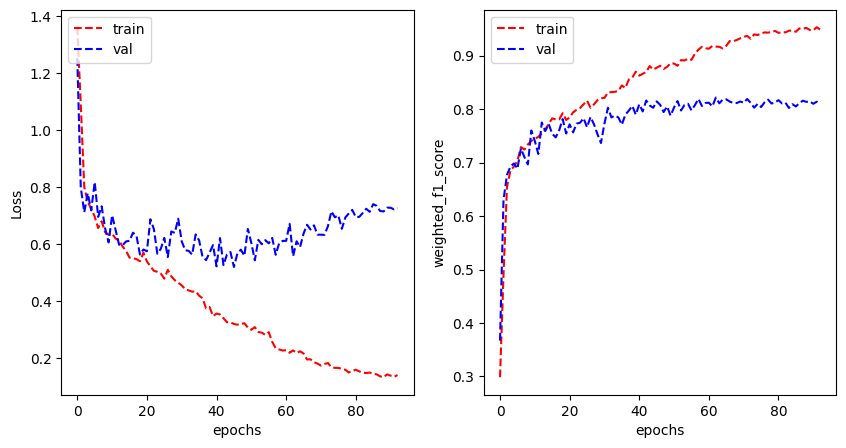

Best validation weighted F1: 0.8217
Best parameters: {'activation': 'leaky_relu', 'dropout_factor': 0, 'l2_lambda': 0, 'padding': 'same'}
14/14 ━━━━━━━━━━━━━━━━━━━━ 2s 89ms/step
Classification Report:
              precision    recall  f1-score   support

           0      0.789     0.767     0.778       288
           1      0.697     0.838     0.761       371
           2      0.944     0.881     0.911       921
           3      0.529     0.513     0.521       158

    accuracy                          0.819      1738
   macro avg      0.740     0.750     0.743      1738
weighted avg      0.828     0.819     0.822      1738



In [ ]:
param_grid = { #Representative paramater grid for hyperparamater tuning. I tried many more values like tanh, gelu etc
    'activation': ['leaky_relu','elu'],
    'padding': ['same', 'valid'],
    'l2_lambda': [0, 0.01,0.1],
    'dropout_factor' : [0, 0.25]
}

best_model_CT = grid_search( #Will search all combinations of the above hyper-parameters and will return best model based on weighted f1 score.
    model_builder_fn=build_cnn_mlp_CT,
    param_grid_dict=param_grid,
    train_data=train_generator_CT_da, #The augmented data with no oversampling was deemed the best from before, so is used here.
    val_data=validation_generator_CT,
    num_classes=OUTPUT_CLASSES_CT
)
# Print classification report for validation set
cr = get_classification_report(best_model_CT, validation_generator_CT)
print("Classification Report:")
print(cr)

### Final Model
Test Performance of the best overall model with ideal hyperparameters

In [ ]:
# Print classification report for the test set
cr = get_classification_report(best_model_CT, test_generator_CT)
print("Classification Report:")
print(cr)

11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 127ms/step
Classification Report:
              precision    recall  f1-score   support

           0      0.733     0.601     0.661       301
           1      0.650     0.797     0.716       340
           2      0.900     0.872     0.886       611
           3      0.371     0.359     0.365       128

    accuracy                          0.747      1380
   macro avg      0.663     0.658     0.657      1380
weighted avg      0.753     0.747     0.747      1380



## **Improved Cell Type Model using Extra Data**

* In this section we attempted to improve the perfromance of the CellType model by using semi-supervised learning.
* We used the best cellType model to predict values in the extra data set, and used those predicted values with the original training set to train a new model.
* We applied the same hyperparamaters as the best model, and used data augmentation as well, to control for all factors, and see if this methods worked.

In [ ]:
extra_datagen = ImageDataGenerator(rescale=1./255) #Scale the extra image data

predict_generator = extra_datagen.flow_from_dataframe( # Create a generator for the extra data so we can predict the values.
    dataframe=extra_data,
    directory=None,
    x_col="image_path",
    y_col=None,
    target_size=(27, 27),
    batch_size=128,
    shuffle=False,
    class_mode=None  # No labels
)

Found 10384 validated image filenames.


In [ ]:
predictions = best_model_CT.predict(predict_generator) # Predict the output probabilities
label_map = train_generator_CT.class_indices #Get the labels
predicted_indices = np.argmax(predictions, axis=1) #Use the maximum probability to predict the class
labels = dict((v, k) for k, v in label_map.items()) #Map the predictions to the class
predicted_labels = [labels[i] for i in predicted_indices] #Get the predicted labels and append them to dataframe
extra_data['cellType'] = predicted_labels

 3/82 ━━━━━━━━━━━━━━━━━━━━ 2s 27ms/step

82/82 ━━━━━━━━━━━━━━━━━━━━ 4s 44ms/step


In [ ]:
extra_subset = extra_data[['image_path', 'cellType']] #
train_subset = train_data[['image_path', 'cellType']]

# Concatenate the two dataframes
combined_data = pd.concat([train_subset, extra_subset], ignore_index=True)
combined_data

,image_path,cellType
0,./patch_images/307.png,2
1,./patch_images/16741.png,3
2,./patch_images/13942.png,2
3,./patch_images/16923.png,1
4,./patch_images/9360.png,2
...,...,...
17157,./patch_images/20028.png,0
17158,./patch_images/20029.png,0
17159,./patch_images/20030.png,2
17160,./patch_images/20031.png,2


In [ ]:
# Using data augmentation as that was the best previously
train_generator_combined = train_datagen_da.flow_from_dataframe(
    dataframe=combined_data,
    directory=None,
    x_col='image_path',
    y_col='cellType',
    target_size=(27, 27),
    batch_size=128,
    shuffle=False,
    class_mode='categorical'
)

Found 17162 validated image filenames belonging to 4 classes.


Epoch 82: early stopping
Restoring model weights from the end of the best epoch: 52.


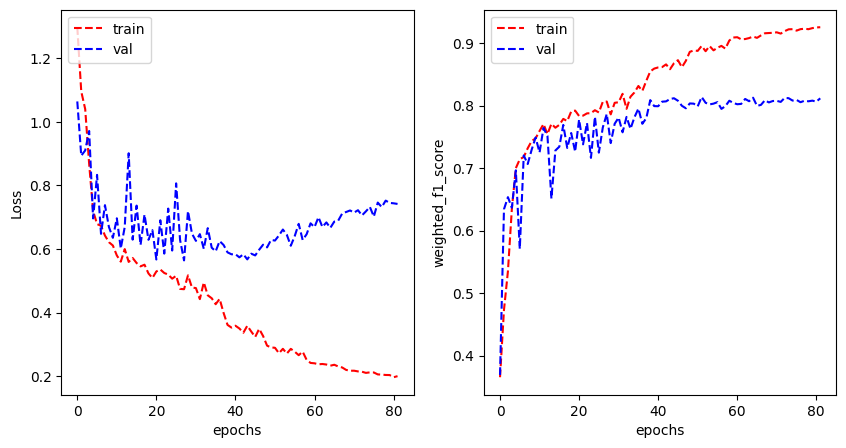

14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 52ms/step
Classification Report Validation:
              precision    recall  f1-score   support

           0      0.833     0.712     0.768       288
           1      0.655     0.876     0.750       371
           2      0.930     0.881     0.905       921
           3      0.589     0.462     0.518       158

    accuracy                          0.814      1738
   macro avg      0.752     0.733     0.735      1738
weighted avg      0.824     0.814     0.814      1738



In [ ]:
#Train the new model with the same hyper-paramters as the previous bets model

improved_ct = build_cnn_mlp_CT(num_classes=OUTPUT_CLASSES_CT, activation='leaky_relu', padding='same', l2_lambda=0,dropout_factor=0)
improved_ct.compile(optimizer='adam', loss=tf.keras.losses.CategoricalCrossentropy(from_logits=False), metrics=[tf.keras.metrics.F1Score(average='weighted',name='weighted_f1')])

improved_ct_history = improved_ct.fit(train_generator_combined, validation_data = validation_generator_CT, epochs=100,callbacks=[early_stop,lr_callback], verbose=0)
#Plot Learning Curve
plot_learning_curve(improved_ct_history.history['loss'], improved_ct_history.history['val_loss'],
                    improved_ct_history.history['weighted_f1'], improved_ct_history.history['val_weighted_f1'],
                    metric_name='weighted_f1_score')
#Print classification report for validation set
cr = get_classification_report(improved_ct, validation_generator_CT)
print("Classification Report Validation:")
print(cr)

In [ ]:
# Test the improved model on the test dataset
cr = get_classification_report(improved_ct, test_generator_CT)
print("Classification Report Test:")
print(cr)

11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 51ms/step
Classification Report Test:
              precision    recall  f1-score   support

           0      0.750     0.618     0.678       301
           1      0.605     0.841     0.704       340
           2      0.925     0.848     0.885       611
           3      0.374     0.289     0.326       128

    accuracy                          0.744      1380
   macro avg      0.663     0.649     0.648      1380
weighted avg      0.757     0.744     0.743      1380



# **Results**

## Generalizability
The test set, kept separate throughout, was used to evaluate how well the best models generalise. Compared to validation performance, test scores dropped by about 0.05, indicating some generalisation gap.

### isCancerous: Base Model vs Final Model

| Model Name                                | Validation Accuracy (%) | Validation Weighted F1 Score | Test Accuracy (%) | Test Weighted F1 Score |
|------------------------------------------|--------------------------|------------------------------|--------------------|------------------------|
| Base Model                                 |    89.8            |           0.898                   | Not reported                 | Not reported                     |
| Oversampled Model (isCancerous)              |      89.9               |       0.899                       | Not reported                 | Not reported                     |
| Data Augmentation Model (isCancerous)        |         90.8         |        0.908                | Not reported                 | Not reported                     |
| **Final Model (isCancerous)**                |           90.8            |         0.908                 |    86.4            |       0.865             |

### isCancerous: Comparing with similar predictive models (Independent Evaluation)

| Model / Study              | Test Accuracy (%) | Test Recall (%) | Test Weighted F1 Score |
|---------------------------|--------------------|------------------|------------------------|
| EfficientNetB0            | 94.15              | 0.947            | 0.942*                  |
| InceptionResNetV2         | 94.90              | 0.951            | 0.949*                  |
| Xception                  | 96.30              | 0.971            | 0.963*                  |
| EfficientNetV2M           | 97.55              | 0.981            | 0.975*                  |
| CMNV2          | 99.95              | 0.999              | 0.999*                 
| **Final Model (isCancerous)** | 86.4       |     0.863        | 0.865                  |

\* = Unweighted F1.

Source: (Girepunje & Singh, 2024; Kumar & Misra, 2024)

### cellType: Base Model vs Final Model
I only used the testing set on the final model and semi supervised model for comparison.

| Model                                 | Validation Accuracy (%) | Validation Weighted F1 Score | Test Accuracy (%) | Test Weighted F1 Score |
|---------------------------------------|--------------------------|------------------------------|--------------------|--------------------------|
| Base Model (Simple Architecture)                            | 75.4                    | 0.741                        | Not reported                 | Not reported                       |
| Improved Model (Deeper Architecture)                       | 76.0                     | 0.754                        | Not reported                 | Not reported                       |
| Oversampled Model                     | 74.5                    | 0.748                        | Not reported                 | Not reported                       |
| Data Augmentation Model               | 81.4                     |  0.811                        | Not reported                 | Not reported                       |
| Data Augmentation + Oversampled Model | 78.0                     | 0.784                        | Not reported                 | Not reported                       |
| **Final Model (cellType)** | 81.9                | 0.822                        | 74.7               | 0.747                    |
| **Semi-Supervised Model**                 | 81.4                     | 0.814                        | 74.4               | 0.743                    |



### cellType: Comparing with similar predictive models (Independent Evaluation)

| Model Name             | Testing Accuracy (%) | Testing Weighted F1 Score |
|------------------------|----------------------|----------------------------|
| AlexNet                | 76.96                | 0.7664                     |
| CIFAR-VGG              | 75.94                | 0.7708                     |
| GoogLeNet              | 78.99                | 0.7856                     |
| RCCNET                 | 80.61                | 0.7887                     |
| **Final Model (cellType**) | 74.7                | 0.747                     |


Source: (Shabbeer Basha et al., 2018)


# **Discussion**

## **Predicting 'isCancerous'**

## Observations: 'isCancerous' Model

We evaluated many model configurations, with only a subset shown; several additional architectures were tested during development.

* The base model for isCancerous prediction performed well, achieving a macro F1-score and accuracy of 0.898.

* Augmentation and oversampling were tested to address class imbalance, with augmentation yielding better results and less overfitting.

* A combination of augmentated and oversampled data was trialled however did not perform well so was omitted from this notebook.

* The final model achieved a weighted F1 of 0.908. Simpler architectures were favoured, as deeper models offered negligible performance gains and increased training time.

* Early stopping and adaptive learning rates improved both performance and training efficiency.

* ReLU was the most effective activation in convolutional layers; softmax outperformed sigmoid in the output layer.

* L2 regularisation improved generalisation by penalising large weights, promoting simpler models and training stability (Alzubaidi et al., 2021).

* 'Same' padding outperformed 'valid' in preserving spatial dimensions.

* Batch normalisation had no significant impact.

* Mild dropout in the final convolutional layer improved performance by reducing reliance on specific neurons and enhancing robustness (Alzubaidi et al., 2021).

* Increasing the filter size to (5,5) in early layers led to minor performance gains.

* Compared to state-of-the-art models, performance lagged — likely due to dataset limitations and restricted compute resources.

## **Predicting 'cellType'**
* The improved model outperformed the base model (F1: 0.754 vs. 0.741), likely due to its increased depth and ability to learn more complex features under identical training settings.

* Early stopping partially mitigated overfitting by restoring the best weights before validation performance declined.

* Oversampling alone did not improve performance, likely due to overfitting to duplicated minority samples and limited generalisation.

* Data augmentation alone gave the best results, suggesting that added variability was more effective than balancing class counts.

* Combining augmentation with oversampling slightly reduced performance, possibly due to redundancy from duplicated examples.

* The final model used data augmentation and adopted the best hyperparameters from tuning: leaky ReLU, ‘same’ padding, and no dropout or L2 regularisation.

* Dropout and L2 were excluded as they offered no additional benefit when early stopping and augmentation were already in place.

* Leaky ReLU improved training stability by maintaining gradient flow on negative inputs, avoiding inactive neurons.


### **Self Supervised Learning**
*  Self-supervised learning yielded only marginal improvement, suggesting that the pseudo-labels introduced noise that offset the benefits of the larger training set.
* Since the model trained on its own predictions, any initial biases or misclassifications may have been reinforced, limiting generalisation.

### **Independant Analysis**

* Our final model achieved a test F1-score of 0.756, performing competitively against models in the RCCNet paper (Shabbeer Basha et al., 2018), including RCCNet (0.7887), AlexNet (0.7664), and CIFAR-VGG (0.7708).

* Unlike these models, which used larger inputs (32×32) and deeper architectures, our model was trained on 27×27 images with fewer parameters and limited compute, highlighting its efficiency.

# **Strengths and Limitations**

**Strengths:**

* The dataset contains approximately 10,000 labelled images, which is substantial for training shallow neural networks and larger than many published histopathology datasets.

* Convolutional neural networks (CNNs) were used, which are the standard for image classification due to their ability to learn features directly from raw pixel data.

* Best-practice techniques such as oversampling, data augmentation, L2 regularisation, and dropout were applied to improve model generalisability.

* Appropriate evaluation metrics (e.g. weighted F1-score) were selected for the imbalanced data, aligning with those used in comparable published models.
   

**Limitations:**

* The images used for training are only 27 × 27 pixels, each showing a single cell. This narrow field of view contrasts with clinical diagnosis, which relies on whole slide images (WSIs) that capture thousands of cells and surrounding tissue context.
* Many published models use larger images (e.g. 224 × 224), allowing them to learn spatial patterns across broader tissue structures, which are often critical for accurate cancer detection (Hamida et al., 2021; Kumar & Misra, 2024).
* Training was conducted entirely on free Google Colab resources, limiting available GPU time and memory. This constrained the complexity of models we could experiment with and restricted the length of training runs.
* The dataset is imbalanced, with some cell types over-represented and only epithelial cells labelled as cancerous. This may lead the model to associate ‘epithelial’ with ‘cancer’ based on label structure rather than visual features.
* There are no healthy examples of epithelial cells, which prevents the model from learning the visual differences between normal and abnormal epithelial tissue — a significant issue in the context of cancer diagnosis.



# **Appendix**

## **Conclusion & Future Work**

This study explored the application of CNNs for binary and multiclass classification tasks using histopathology images, aiming to detect whether a cell is cancerous, and identify the cell type. The models performed surprisingly well, especially considering the limited computational resources available. The data used consisted of approximatley 10,000 images that included individual cells and were pre-labelled. This is a significant stretch from how cancer is diagnosed in practice, where WSIs and tissue context are important. Additionally, the data was imbalanced, with no exmaples of healthy epithelial cells.

There is plenty of room to build on this. Firstly, using a balanced dataset with more examples of healthy tissue, followed by using larger images in conjunction known deeper architectures as presented by Kumar & Misra (2024).

This work lays a solid foundation for future exploration of image classification using CNNs, and also proves that even with limited tools, it is possible to obtain meaningful results.


## **References**


Alzubaidi, L., Zhang, J., Humaidi, A. J., Al-Dujaili, A., Duan, Y., Al-Shamma, O., Santamaria, J., Fadhel, M.A., Al-Amidie, M., & Farhan, L. (2021). Review of deep learning: concepts, cnn architectures, challenges, applications, future directions. *Journal of Big Data*, 8(53), 1-74. https://journalofbigdata.springeropen.com/articles/10.1186/s40537-021-00444-8

Chawla, N. V., Bowyer, K. W., Hall, L. O., & Kegelmeyer, W. P. (2002). SMOTE: Synthetic Minority Over-sampling Technique. Journal of Artificial Intelligence Research, 16(16), 321–357. https://doi.org/10.1613/jair.953

Girepunje, S., & Singh, P. (2024). EffiSANet: EfficientNet Integration with Self-attention for Colorectal Cancer Classification. *Lecture Notes in Electrical Engineering*, 1262, 271-283. https://doi.org/10.1007/978-981-97-7794-5_22

Hamida, A. B., Devanne, M., Weber, J., Truntzer, C., Derangere, V., Ghiringhelli, F., Forestier, G., & Wemmert, C. (2021). Deep learning for colon cancer histopathological images analysis. *Computers in Biology and Medicine*, 136, 104730. https://www.sciencedirect.com/science/article/pii/S001048252100524

Kapoor, S., & Narayanan, A. (2023). Leakage and the reproducibility crisis in machine-learning-based science. *Patterns*, 4(9), 100804. https://www.sciencedirect.com/science/article/pii/S2666389923001599

Kashyap, P. (2024). Image normalization in PyTorch: From tensor conversion to scaling. *Medium*, . https://medium.com/@piyushkashyap045/image-normalization-in-pytorch-from-tensor-conversion-to-scaling-3951b6337bc8

Kumar, A., & Misra, N. K. (2024). Colon cancer classification and detection by novel CMNV2 model and methods of deep learning. *Neural Computing and Applications*, 37, 25-41. https://doi.org/10.1007/s00521-024-10563-x

Mosquera, C., Ferrer, L., Milone, D. H., Luna, D., & Ferrante, E. (2024). Class imbalance on medical image classification: towards better evaluation practices for discrimination and calibration performance. *European Radiology*, 34, 7895-7903. https://doi.org/10.1007/s00330-024-10834-0

Mujahid, M., Kına, E., Rustam, F., Villar, M. G., Alvarado, E. S., De La Torre Diez, I., & Ashraf, I. (2024). Data oversampling and imbalanced datasets: An investigation of performance for machine learning and feature engineering. *Journal of Big Data*, 11(1), 87. https://doi.org/10.1186/s40537-024-00943-4

Neto, E. C., Pratap, A., Perumal, T. M., Tummalacherla, M., Bot, B. M., Trister, A. D., Friend, S. H., Mangravite, L., & Omberg, L. (2017). Learning disease vs participant signatures: A permutation test approach to detect identity confounding in machine learning diagnostic applications. *arXiv preprint*, . https://arxiv.org/abs/1712.03120

Saeb, S., Lonini, L., Jayaraman, A., Mohr, D. C., & Kording, K. P. (2017). The need to approximate the use-case in clinical machine learning. *GigaScience*, 6(5), 1-9. https://doi.org/10.1093/gigascience/gix019  

Shabbeer Basha, S. H., Ghosh, S., Kishan Babu, K., Ram Dubey, S., Pulabaigari, V., & Mukherjee, S. (2018). RCCNet: An efficient convolutional neural network for histological routine colon cancer nuclei classification. 2018 15th International Conference on Control, Automation, Robotics and Vision (ICARCV), 1222–1227. https://doi.org/10.1109/icarcv.2018.8581147

Xu, M., Yoon, S., Fuentes, A., & Park, D. S. (2023). A comprehensive survey of image augmentation techniques for deep learning. *Pattern Recognition*, 137, 109347. https://www.sciencedirect.com/science/article/pii/S0031320323000481

